In [60]:
import os
import pandas as pd
import matplotlib.pyplot as plt

## Data Processing

In [61]:
# Load Data
dir_name = "glassnode"
file_name = "glassnode_BTC_tier1.csv"

glassnode_btc = pd.read_csv(os.path.join(dir_name, file_name))

In [62]:
# Select endogenous and exogenous columns
endg_cols = ['close']
exog_cols = ['active_count', 'receiving_count', 'sending_count', 'rate', 'gas_price_median',
             'block_count', 'block_size_mean', 'gas_limit_tx_median', 'hash_rate_mean',
             'count', 'difficulty_latest', 'sopr', 'transfers_rate', 'fear_greed']

btc_df = glassnode_btc[endg_cols + exog_cols].copy()

# process 0. convert dtype to float
btc_df = btc_df.astype(float)

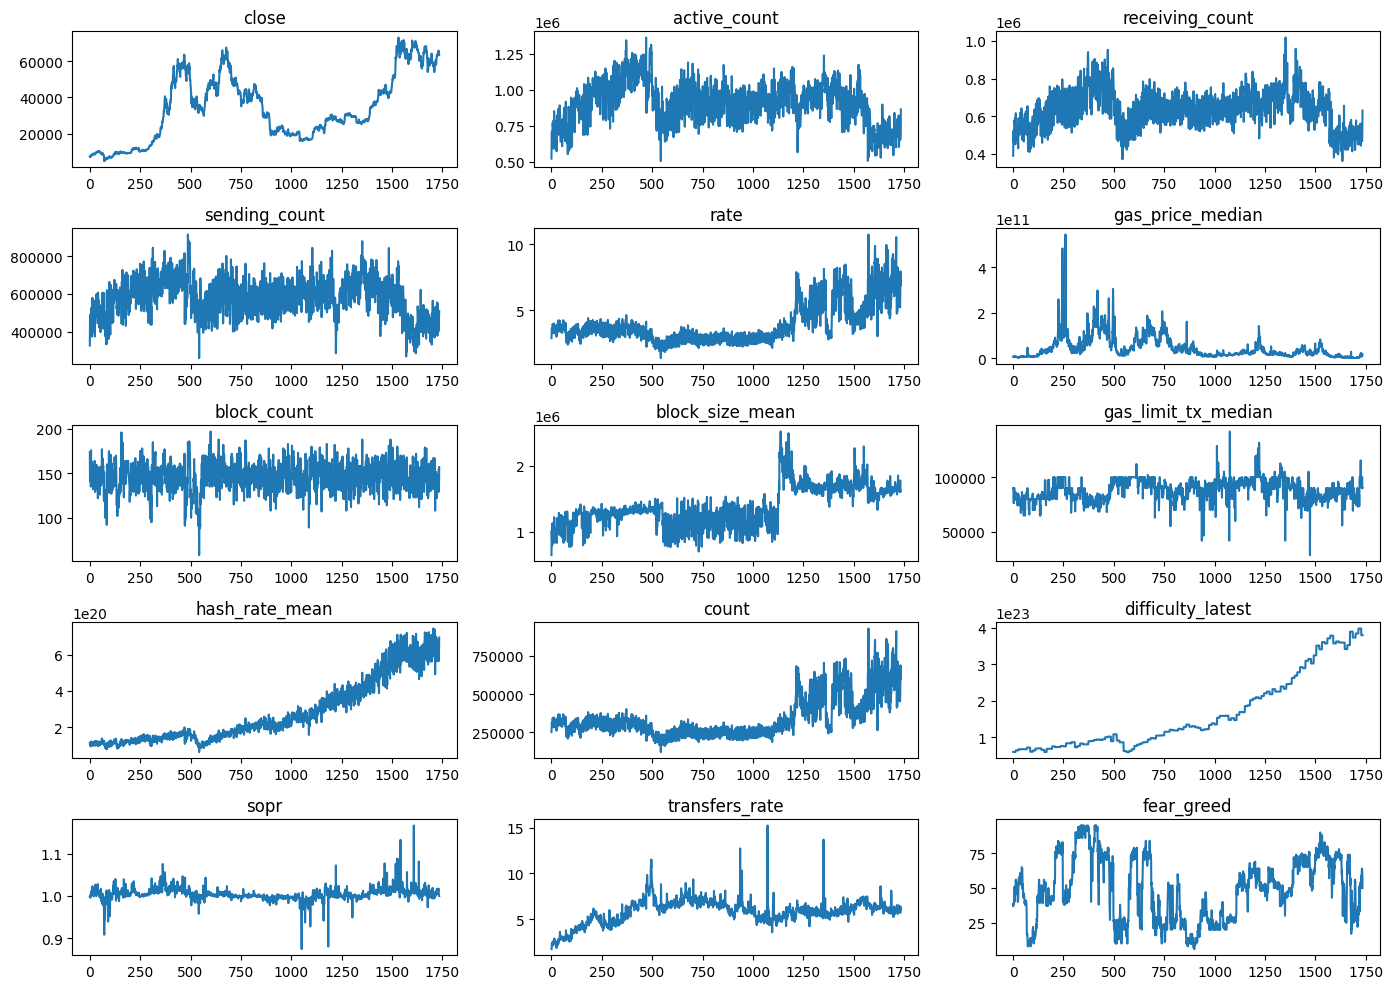

In [63]:
nrows = 5
ncols = 3

fig, axs = plt.subplots(nrows, ncols, figsize=(14, 10))
for i, colname in enumerate(btc_df.columns):
    nrow = i // ncols
    ncol = i % ncols
    btc_df[colname].plot(ax=axs[nrow][ncol])
    axs[nrow][ncol].set_title(colname)
    
plt.tight_layout()    

In [64]:
# processing data  
# Trend Shift happend on 'block_size_mean'.  
# we will drop this column for now. (mayby treat it later)

# process 1. drop 'block_size_mean'
processed_btc_df = btc_df.drop('block_size_mean', axis=1).copy()
exog_cols = [col for col in exog_cols if col != "block_size_mean"]

# # process 2. detrend exog variables by subtracting 3 days moving average  
# nlag = 3
# processed_btc_df[exog_cols] = processed_btc_df[exog_cols] - processed_btc_df[exog_cols].rolling(window=nlag).mean()

# process 3. convert exog and endog data to change ratio data 
processed_btc_df = processed_btc_df.pct_change(fill_method=None)

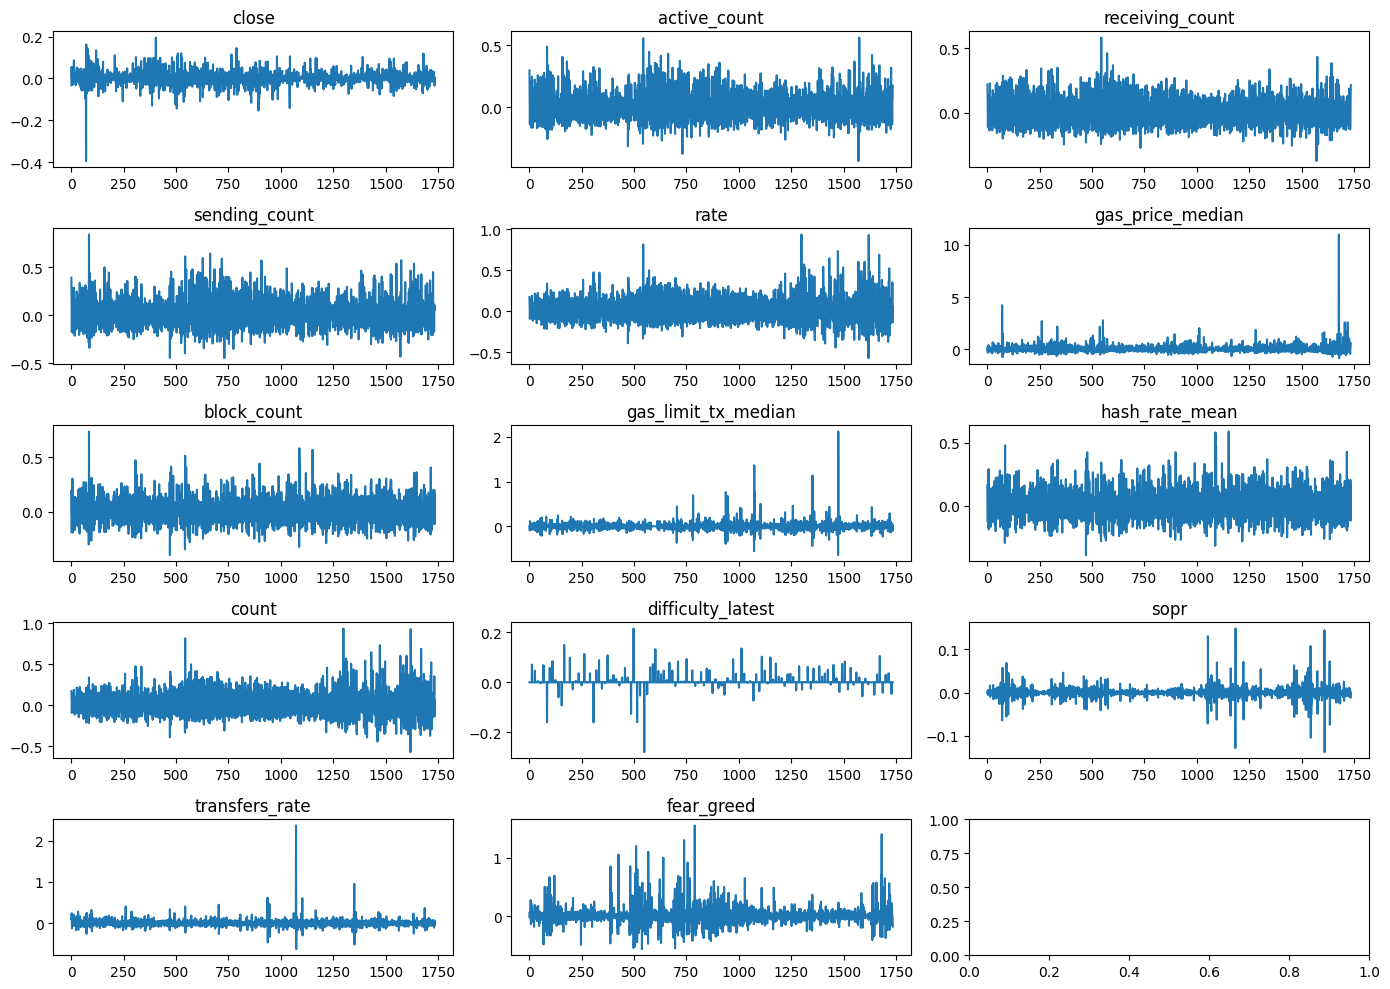

In [65]:
nrows = 5
ncols = 3

fig, axs = plt.subplots(nrows, ncols, figsize=(14, 10))
for i, colname in enumerate(processed_btc_df.columns):
    nrow = i // ncols
    ncol = i % ncols
    processed_btc_df[colname].plot(ax=axs[nrow][ncol])
    axs[nrow][ncol].set_title(colname)
    
plt.tight_layout()    

In [70]:
# There are many zero component in 'difficulty_latest".  
# we drop it for now.  

# process 4. drop 'difficulty_latest' col
processed_btc_df = processed_btc_df.drop("difficulty_latest", axis=1)

# process 5. drop rows that has NaN value for at least one column.  
processed_btc_df = processed_btc_df.dropna()

In [71]:
# Check Correlation
processed_btc_df.corr()

,close,active_count,receiving_count,sending_count,rate,gas_price_median,block_count,gas_limit_tx_median,hash_rate_mean,count,sopr,transfers_rate,fear_greed
close,1.000000,-0.015558,0.024607,-0.035827,0.023133,-0.120636,-0.030368,-0.032209,-0.031652,0.023133,0.230292,0.054510,-0.041743
active_count,-0.015558,1.000000,0.825518,0.952378,0.544594,0.286552,0.406295,0.035128,0.382544,0.544594,0.044332,0.150688,0.022583
receiving_count,0.024607,0.825518,1.000000,0.670594,0.686770,0.324215,0.273582,0.001079,0.249838,0.686770,0.027397,0.172432,0.013627
sending_count,-0.035827,0.952378,0.670594,1.000000,0.503238,0.203859,0.490872,0.034790,0.469344,0.503238,0.039502,0.098432,0.022099
rate,0.023133,0.544594,0.686770,0.503238,1.000000,0.109857,0.433835,-0.001419,0.415284,1.000000,0.004124,0.071863,0.017884
gas_price_median,-0.120636,0.286552,0.324215,0.203859,0.109857,1.000000,-0.011152,0.014889,-0.007360,0.109857,-0.048205,0.179106,-0.025297
block_count,-0.030368,0.406295,0.273582,0.490872,0.433835,-0.011152,1.000000,0.019495,0.981109,0.433835,0.003588,-0.032450,0.015406
gas_limit_tx_median,-0.032209,0.035128,0.001079,0.034790,-0.001419,0.014889,0.019495,1.000000,0.017956,-0.001419,-0.007241,-0.409896,-0.022539
hash_rate_mean,-0.031652,0.382544,0.249838,0.469344,0.415284,-0.007360,0.981109,0.017956,1.000000,0.415284,-0.005433,-0.035239,0.010105
count,0.023133,0.544594,0.686770,0.503238,1.000000,0.109857,0.433835,-0.001419,0.415284,1.000000,0.004124,0.071863,0.017884


In [75]:
# Grouping variables with high correlation
transaction_nodes = [
    "active_count", 
    "receiving_count",
    "sending_count",
    "count",  
    "rate", 
]

mining_nodes = [
    "block_count", 
    "hash_rate_mean", 
]

# # left columns:
# "gas_price_median"
# "gas_limit_tx_median"
# "sopr"
# "fear_greed"

In [79]:
# Combine variables in same group by averaging each values because effect of nodes may be confused by confounders  
# process 6. Combine variables in same group by averaging each values 
processed_btc_df['transaction'] = processed_btc_df[transaction_nodes].mean(axis=1)
processed_btc_df['mining'] = processed_btc_df[mining_nodes].mean(axis=1)

processed_btc_df = processed_btc_df.drop(transaction_nodes + mining_nodes, axis=1)

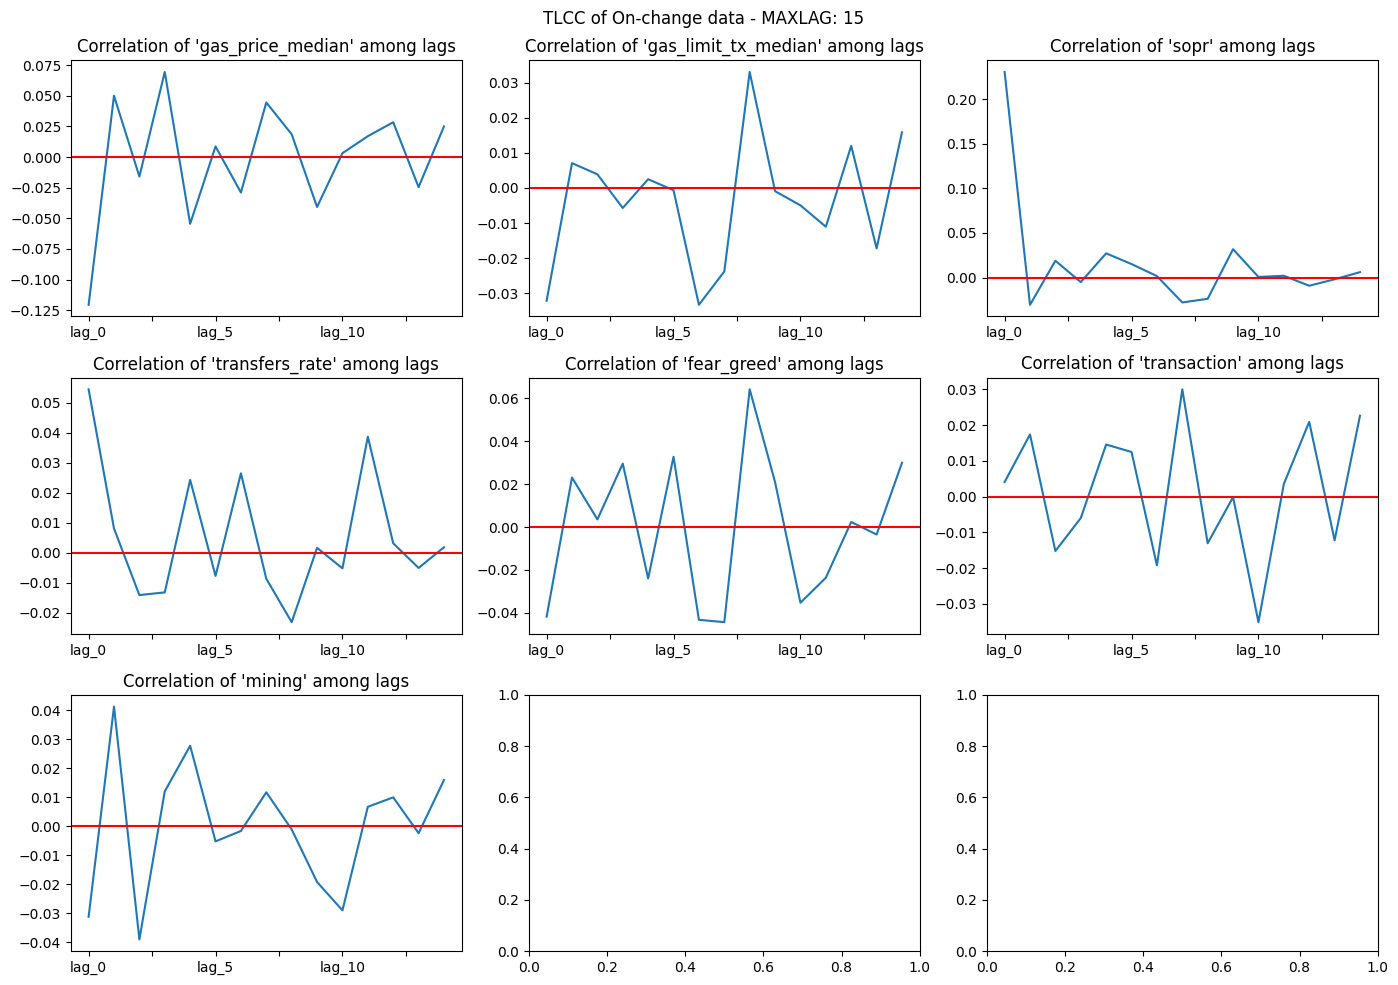

In [89]:
# TLCC (Time lagged Cross Correlation)
# Analyze lagged correlation of on-chain data with "close": 1 day BTC Return 

maxlag = 15
corr_list = []

for lag in range(maxlag):
    df_shifted = processed_btc_df.drop(columns=['close']).shift(lag)
    df_shifted['close'] = processed_btc_df['close']
    
    corr_ser = df_shifted.corr()['close']
    corr_ser.name = f"lag_{lag}"
    corr_list.append(corr_ser)
    
corr_df = pd.concat(corr_list, axis=1).T
corr_df = corr_df.drop('close', axis=1)

nrows = 3
ncols = 3
fig, ax = plt.subplots(nrows, ncols, figsize=(14, 10))
for i, col_name in enumerate(corr_df.columns):
    row = i // ncols
    col = i % ncols
    corr_df[col_name].plot(ax=ax[row][col])
    ax[row][col].set_title(f"Correlation of '{col_name}' among lags")
    ax[row][col].axhline(y=0, color='r')
    
plt.suptitle(f"TLCC of On-change data - MAXLAG: {maxlag}")
plt.tight_layout()

transaction 관련 변수들을 평균낸 'transaction' 을 제외한 변수들이  
모두 lag_0 에서 큰 correlation을 가짐  
- resolution을 높여 일별 데이터가 아닌 분단위 / 초단위 데이터에서 살펴봐야 함.  

## DoWhy Analysis

In [90]:
from dowhy import CausalModel
import networkx as nx

c:\Users\wklee\Desktop\WKLee\FBA\Capstone\fba-capstone\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [92]:
processed_btc_df.corr()

,close,gas_price_median,gas_limit_tx_median,sopr,transfers_rate,fear_greed,transaction,mining
close,1.000000,-0.120636,-0.032209,0.230292,0.054510,-0.041743,0.004080,-0.031152
gas_price_median,-0.120636,1.000000,0.014889,-0.048205,0.179106,-0.025297,0.224499,-0.009316
gas_limit_tx_median,-0.032209,0.014889,1.000000,-0.007241,-0.409896,-0.022539,0.015372,0.018821
sopr,0.230292,-0.048205,-0.007241,1.000000,-0.008575,0.000183,0.026020,-0.000889
transfers_rate,0.054510,0.179106,-0.409896,-0.008575,1.000000,0.019213,0.123434,-0.033993
fear_greed,-0.041743,-0.025297,-0.022539,0.000183,0.019213,1.000000,0.021894,0.012839
transaction,0.004080,0.224499,0.015372,0.026020,0.123434,0.021894,1.000000,0.471681
mining,-0.031152,-0.009316,0.018821,-0.000889,-0.033993,0.012839,0.471681,1.000000


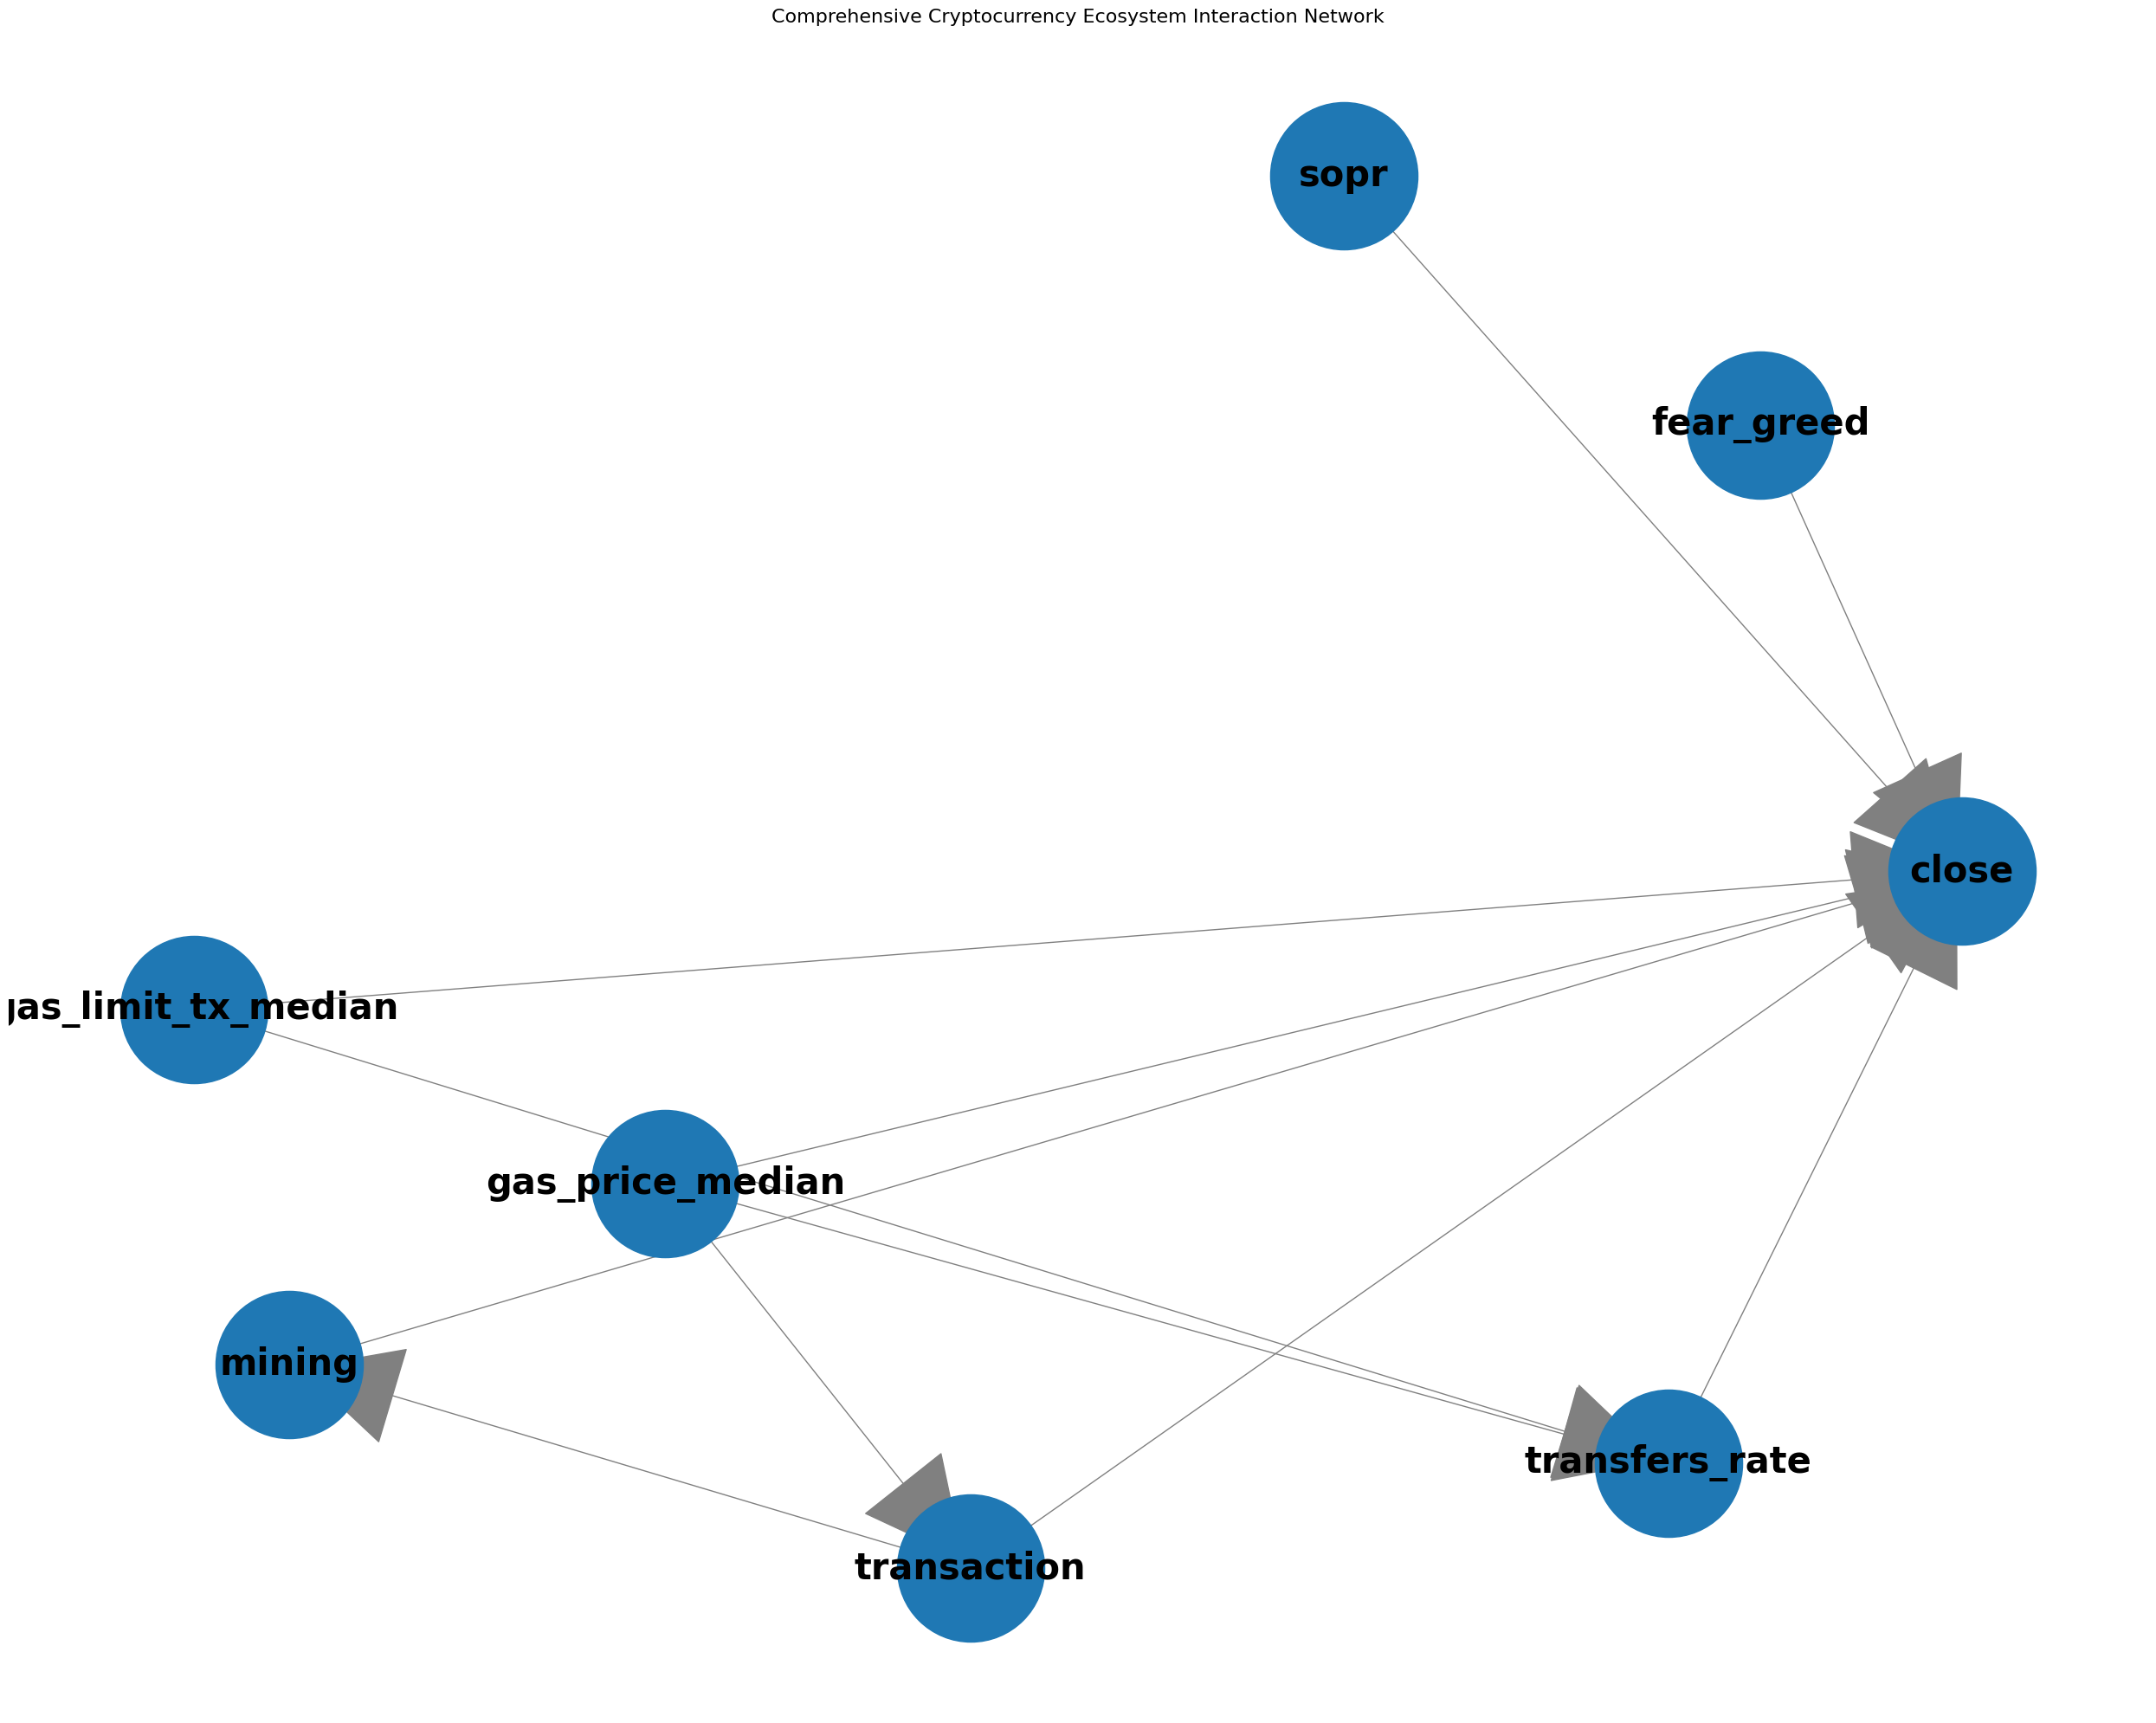

In [94]:
def create_comprehensive_crypto_dag():
    G = nx.DiGraph()

    # 모든 노드 추가
    all_nodes = tuple(processed_btc_df.columns)
    G.add_nodes_from(all_nodes)


    # 복잡한 상호작용 엣지 추가
    edges = [
        # on-chain → close
        ("gas_price_median", "close"),
        ("gas_limit_tx_median", "close"),
        ("sopr", "close"),
        ("transfers_rate", "close"),
        ("fear_greed", "close"),
        ("transaction", "close"),
        ("mining", "close"),

        # 내부 노드 간 상호작용
        ("gas_price_median", "transfers_rate"),
        ("gas_limit_tx_median", "transfers_rate"),
        ("gas_price_median", "transaction"),
        ("transaction", "mining"),
    ]
    G.add_edges_from(edges)

    # 시각화
    plt.figure(figsize=(25, 20))
    pos = nx.spring_layout(G, k=0.7, iterations=50)

    nx.draw_networkx_nodes(G, pos, node_size=15000, alpha=1)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, alpha=1, arrowsize=200)
    nx.draw_networkx_labels(G, pos, font_size=30, font_weight='bold')

    plt.title("Comprehensive Cryptocurrency Ecosystem Interaction Network", fontsize=16)
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    return G

graphs = create_comprehensive_crypto_dag()

In [99]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.SettingWithCopyWarning)
    
model = CausalModel(
	data = processed_btc_df.dropna(), # some pandas dataframe
	treatment="sopr",
	outcome="close",
	graph="\n".join(nx.generate_gml(graphs))
)

In [100]:
identified_estimand = model.identify_effect()
causal_estimate = model.estimate_effect(identified_estimand, method_name="backdoor.linear_regression")

In [102]:
print(causal_estimate)

*** Causal Estimate ***

## Identified estimand
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
   d             
───────(E[close])
d[sopr]          
Estimand assumption 1, Unconfoundedness: If U→{sopr} and U→close then P(close|sopr,,U) = P(close|sopr,)

## Realized estimand
b: close~sopr+sopr*mining+sopr*transfers_rate+sopr*transaction+sopr*gas_price_median+sopr*gas_limit_tx_median+sopr*fear_greed
Target units: 

## Estimate
Mean value: 0.6276621364698113
### Conditional Estimates
__categorical__mining  __categorical__transfers_rate  __categorical__transaction  __categorical__gas_price_median  __categorical__gas_limit_tx_median  __categorical__fear_greed
(-0.397, -0.0962]      (-0.635, -0.0477]              (-0.354, -0.088]            (-0.845, -0.182]                 (-0.645, -0.0465]                   (-0.0682, -0.0156]          -0.187774
                                                                                      